# Kiểm tra overfit và giải thích Direction LSTM (so với XGBoost)

Câu hỏi: LSTM có học quy luật thật, hay chỉ khớp nhiễu của dữ liệu train? Kết quả của nó có bền không, và nó dựa vào đâu?

| # | kiểm tra | dấu hiệu overfit |
|---|---|---|
| 1 | Số epoch dừng sớm, mức giảm log-loss trên tập es so với đoán theo tỉ lệ lớp (từ cache) | dừng ở epoch 1–2, es gần như không tốt hơn đoán theo tỉ lệ lớp |
| 2 | Khoảng cách train / es / cal / test (log-loss, AUC chạm trước) theo quý, so với XGBoost; đường học | train tốt hơn hẳn test, khoảng cách lớn hơn XGB |
| 3 | **Null test:** train trên nhãn bị dịch vòng ≥ 30 ngày (giữ tự tương quan, phá quan hệ feature–nhãn) | null vẫn có AUC > 0.5 hoặc vẫn có lãi, tức có rò rỉ / ăn may |
| 4 | Độ đồng thuận giữa các seed và giữa LSTM với XGB | các seed LSTM rất khác nhau, tức phương sai cao |
| 5 | **Giải thích:** permutation importance (từng feature, nhóm có hướng / vị thế) và che bớt các nến cũ của chuỗi | dựa vào vài feature lạ; không dùng tới lịch sử chuỗi |
| 6 | **Độ bền theo siêu tham số:** 4 biến thể LSTM, gộp 50/50 với XGB, 3 seed, dev + test | kết quả đổi mạnh khi đổi siêu tham số nhỏ |
| 7 | Kiểm tra không nhìn tương lai: đổi feature các nến sau t thì dự báo tại t không đổi | dự báo đổi |

Mục 2, 3, 5, 7 train lại 1 seed (1000) cho mỗi quý (GPU, vài chục phút). Mục 6 train Direction LSTM cho 4 biến thể × 20 quý × 3 seed, mất khoảng 1–2 giờ, có cache. Kết quả lưu ở `artifacts/1h_strategy_v2/exp_lstm_overfit/`.

In [1]:
import os, sys, json
from dataclasses import replace
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "model_training").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "model_training"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
import strategy_h1 as st
import nn_models as nm

pd.set_option("display.width", 240, "display.max_columns", 50)
cfg = st.load_locked("artifacts/1h_strategy_v2/config_locked.json")
XG = replace(cfg, model_kind="xgb")
LS = replace(cfg, model_kind="lstm", nn_params={})
OUT = Path(cfg.output_dir) / "exp_lstm_overfit"
OUT.mkdir(parents=True, exist_ok=True)
D = st.build(cfg)
P = {k: {ph: st.walk_forward(D, c, ph)[0] for ph in ("dev", "test")} for k, c in (("xgb", XG), ("lstm", LS))}   # cache
W = {"xgb": 0.5, "lstm": 0.5}
P["blend"] = {ph: st.blend_direction({"xgb": P["xgb"][ph], "lstm": P["lstm"][ph]}, W) for ph in ("dev", "test")}
lab = D.ds.labels
y3 = st.direction_labels(D.ds)
touched = (lab["y_touch"] == 1) & (lab["first"] != 0)
up_first = lab["first"] == 1
QS = {ph: [str(q) for q in st.quarters(cfg, ph, D)] for ph in ("dev", "test")}
names = list(D.dir_names)
GROUP = {n: ("vị thế" if i >= 20 else "có hướng") for i, n in enumerate(names)}   # 20 có hướng + 17 vị thế

Dữ liệu: 54,979 nến 1h, 53,522 mẫu (2020-08-30 -> 2026-10-08), touch 92 feature, direction 37 feature, 13s
dev 2022Q1: AUC touch 0.610 | AUC direction 0.616 | train 7,303 | 0s
dev 2022Q2: AUC touch 0.695 | AUC direction 0.536 | train 9,511 | 0s
dev 2022Q3: AUC touch 0.605 | AUC direction 0.520 | train 11,719 | 0s
dev 2022Q4: AUC touch 0.689 | AUC direction 0.601 | train 13,879 | 0s
dev 2023Q1: AUC touch 0.664 | AUC direction 0.675 | train 16,063 | 0s
dev 2023Q2: AUC touch 0.692 | AUC direction 0.588 | train 18,271 | 0s
dev 2023Q3: AUC touch 0.751 | AUC direction 0.565 | train 20,479 | 0s
dev 2023Q4: AUC touch 0.721 | AUC direction 0.566 | train 22,639 | 0s
dev 2024Q1: AUC touch 0.718 | AUC direction 0.571 | train 24,823 | 0s
dev 2024Q2: AUC touch 0.749 | AUC direction 0.587 | train 27,031 | 0s
dev 2024Q3: AUC touch 0.735 | AUC direction 0.585 | train 29,239 | 0s
dev 2024Q4: AUC touch 0.778 | AUC direction 0.626 | train 31,423 | 0s
test 2025Q1: AUC touch 0.763 | AUC direction 0.552 | tr

## 1. Dừng sớm và mức học được trên tập es (từ cache walk-forward, 5 seed)

In [2]:
rows = []
for ph in ("dev", "test"):
    for q in QS[ph]:
        sp = st.fold_split(D, pd.Period(q, "Q"), cfg)
        prior = np.bincount(y3[sp["train"]], minlength=3) / len(sp["train"])
        base_ll = float(-np.mean(np.log(prior[y3[sp["es"]]])))          # đoán theo tỉ lệ lớp của train
        for s in cfg.seeds:
            f = Path(cfg.output_dir) / "folds" / f"lstm_{ph}_{q}_s{s}.npz"
            if not f.exists():
                continue
            m = json.loads(str(np.load(f, allow_pickle=False)["meta"]))
            rows.append({"phase": ph, "quý": q, "seed": s, "epoch tốt nhất": m["dir_rounds"], "es log-loss": m["dir_es_logloss"],
                         "log-loss đoán theo tỉ lệ lớp": base_ll,
                         "es tốt hơn đoán theo tỉ lệ lớp %": (base_ll - m["dir_es_logloss"]) / base_ll * 100})
E = pd.DataFrame(rows)
E.to_csv(OUT / "early_stopping.csv", index=False)
display(E.groupby(["phase", "quý"])[["epoch tốt nhất", "es tốt hơn đoán theo tỉ lệ lớp %"]].agg(["mean", "min", "max"]).round(2))
print("tỉ lệ fold dừng ở epoch <= 2:", round((E["epoch tốt nhất"] <= 2).mean(), 3))

epoch tốt nhất         es tốt hơn đoán theo tỉ lệ lớp %            
                       mean min max                             mean   min   max
phase quý                                                                       
dev   2022Q1            1.4   1   2                             0.87  0.52  1.11
      2022Q2            1.2   1   2                             0.65  0.41  0.87
      2022Q3            1.4   1   2                             1.00  0.39  1.25
      2022Q4            3.6   3   4                             3.78  3.11  4.40
      2023Q1            1.2   1   2                            -0.49 -0.97 -0.06
      2023Q2            3.2   2   5                             6.24  5.76  7.10
      2023Q3            2.2   2   3                             3.59  2.88  4.27
      2023Q4            1.4   1   2                             2.08  1.62  2.43
      2024Q1            2.8   2   4                             6.61  3.80  7.67
      2024Q2            3.2   2   4                             3.71  2.92  3.98
      2024Q3            2.0   1   3                             2.14  1.76  2.48
      2024Q4            2.0   1   5                             1.91  1.19  2.80
test  2025Q1            2.2   1   4                             0.29 -0.52  1.65
      2025Q2            2.4   2   3                             4.10  3.35  5.78
      2025Q3            1.6   1   3                             2.94  1.98  4.00
      2025Q4            1.2   1   2                             2.12  1.00  3.50
      2026Q1            2.0   1   3                             1.97  1.43  2.72
      2026Q2            2.2   2   3                             1.59  1.04  2.00
      2026Q3            2.2   2   3                             3.06  2.57  3.56
      2026Q4            1.6   1   2                             2.83  2.36  3.12

tỉ lệ fold dừng ở epoch <= 2: 0.75


## 2. Khoảng cách train / es / cal / test theo quý: LSTM và XGBoost (seed 1000, train lại)

In [3]:
def ll3(pr, idx):
    return float(-np.mean(np.log(np.clip(pr[np.arange(len(idx)), y3[idx]], 1e-7, 1))))

def auc_dir(pr, idx):
    ok = touched[idx]
    return float(roc_auc_score(up_first[idx][ok], (0.5 + 0.5 * (pr[:, 1] - pr[:, 2]))[ok])) if ok.sum() > 50 else np.nan

MODELS, rows = {}, []
for ph in ("dev", "test"):
    for q in QS[ph]:
        sp = st.fold_split(D, pd.Period(q, "Q"), cfg)
        lm = nm.fit_direction_nn(D, sp, LS, 1000)
        xm, xb = st.fit_direction(D, sp, XG, 1000)
        MODELS[q] = {"sp": sp, "lstm": lm, "xgb": (xm, xb)}
        for part in ("train", "es", "cal", "test"):
            idx = sp[part]
            for k, pr in (("LSTM", lm.predict_proba(idx)), ("XGB", xm.predict_proba(D.xd[idx], iteration_range=(0, xb)))):
                rows.append({"phase": ph, "quý": q, "model": k, "tập": part, "log-loss": ll3(pr, idx), "AUC chạm trước": auc_dir(pr, idx)})
        print(q, "LSTM epoch", lm.best_epoch, "| XGB cây", xb)
G = pd.DataFrame(rows)
G.to_csv(OUT / "gap_by_quarter.csv", index=False)
gap = G.pivot_table(index=["model", "phase"], columns="tập", values=["AUC chạm trước", "log-loss"], aggfunc="mean")
gap[("AUC chạm trước", "train − test")] = gap[("AUC chạm trước", "train")] - gap[("AUC chạm trước", "test")]
gap[("log-loss", "test − train")] = gap[("log-loss", "test")] - gap[("log-loss", "train")]
gap.round(4)

2022Q1 LSTM epoch 1 | XGB cây 84
2022Q2 LSTM epoch 1 | XGB cây 88
2022Q3 LSTM epoch 2 | XGB cây 107
2022Q4 LSTM epoch 4 | XGB cây 219
2023Q1 LSTM epoch 1 | XGB cây 151
2023Q2 LSTM epoch 2 | XGB cây 617
2023Q3 LSTM epoch 3 | XGB cây 630
2023Q4 LSTM epoch 2 | XGB cây 267
2024Q1 LSTM epoch 3 | XGB cây 953
2024Q2 LSTM epoch 4 | XGB cây 611
2024Q3 LSTM epoch 2 | XGB cây 495
2024Q4 LSTM epoch 2 | XGB cây 581
2025Q1 LSTM epoch 1 | XGB cây 180
2025Q2 LSTM epoch 2 | XGB cây 325
2025Q3 LSTM epoch 3 | XGB cây 704
2025Q4 LSTM epoch 1 | XGB cây 668
2026Q1 LSTM epoch 2 | XGB cây 418
2026Q2 LSTM epoch 3 | XGB cây 517
2026Q3 LSTM epoch 2 | XGB cây 1001
2026Q4 LSTM epoch 2 | XGB cây 394


AUC chạm trước                         log-loss                         AUC chạm trước     log-loss
tập                    cal      es    test   train      cal      es    test   train   train − test test − train
model phase                                                                                                    
LSTM  dev           0.5838  0.5843  0.5835  0.6242   1.0056  0.9879  1.0057  1.0041         0.0406       0.0016
      test          0.5438  0.5549  0.5648  0.6193   0.9969  0.9967  1.0099  0.9694         0.0545       0.0405
XGB   dev           0.5898  0.5958  0.5841  0.7456   0.9923  0.9849  0.9920  0.9552         0.1615       0.0368
      test          0.5613  0.5679  0.5698  0.7080   0.9773  0.9810  0.9845  0.9426         0.1381       0.0419

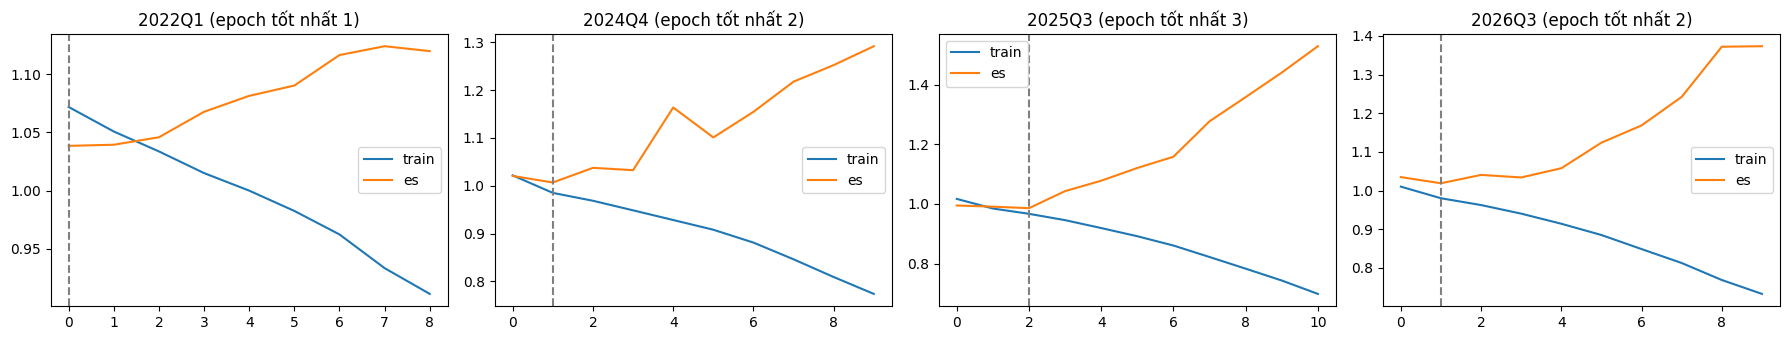

In [4]:
# đường học (train có dropout; es = tập dừng sớm) của 4 quý
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, q in zip(axes, [QS["dev"][0], QS["dev"][-1], QS["test"][2], QS["test"][-2]]):
    m = MODELS[q]["lstm"]
    ax.plot(m.train_history, label="train"); ax.plot(m.history, label="es")
    ax.axvline(m.best_epoch - 1, color="grey", ls="--"); ax.set_title(f"{q} (epoch tốt nhất {m.best_epoch})"); ax.legend()
plt.tight_layout(); plt.show()

## 3. Null test: LSTM train trên nhãn dịch vòng (seed 1000, các quý test)

Nhãn của tập train và es được dịch vòng ≥ 30 ngày. Tự tương quan và tỉ lệ lớp giữ nguyên, nhưng quan hệ giữa feature và nhãn bị phá. Feature và tập test giữ nguyên. Model thật phải tốt hơn hẳn null.

In [5]:
def fit_custom(sp, y_tr, y_es, seed=1000):
    prep = nm.Prep().fit(D.xd[sp["train"]])
    m = nm.NNClassifier("lstm", nm.make_params("lstm", LS.nn_params), 3, seed, device=LS.nn_device, threads=LS.nn_threads)
    m.fit(prep.transform(D.xd), D.ds.timestamp_ns, sp["train"], y_tr, sp["es"], y_es)
    return m

def p_frame(base, preds):
    """P test của XGB với p_up (ensemble và mọi seed) thay bằng dự báo 1 model / quý (preds: quý -> p_up cửa sổ)."""
    Q = base.copy()
    for q, pu in preds.items():
        m = (Q.fold == q).to_numpy()
        for c in [c for c in Q.columns if c == "p_up" or c.startswith("p_up_s")]:
            Q.loc[m, c] = pu
    return Q

rng = np.random.default_rng(0)
real, nulls, rows = {}, {0: {}, 1: {}}, []
for q in QS["test"]:
    sp = MODELS[q]["sp"]
    real[q] = nm.scores(MODELS[q]["lstm"].predict_proba(sp["window"]))[0]
    rows.append({"quý": q, "bản": "LSTM thật", "AUC test": auc_dir(MODELS[q]["lstm"].predict_proba(sp["test"]), sp["test"])})
    for k in nulls:
        sh_tr, sh_es = int(rng.integers(30 * 24, len(sp["train"]) - 30 * 24)), int(rng.integers(30 * 24, max(len(sp["es"]) - 30 * 24, 30 * 24 + 1)))
        m = fit_custom(sp, np.roll(y3[sp["train"]], sh_tr), np.roll(y3[sp["es"]], sh_es % len(sp["es"])))
        nulls[k][q] = nm.scores(m.predict_proba(sp["window"]))[0]
        rows.append({"quý": q, "bản": f"null {k}", "AUC test": auc_dir(m.predict_proba(sp["test"]), sp["test"]), "epoch": m.best_epoch})
N = pd.DataFrame(rows)
display(N.pivot_table(index="quý", columns="bản", values="AUC test").round(3))
display(N.groupby("bản")["AUC test"].mean().round(4))

base = P["xgb"]["test"]
rows = []
for name, preds in [("LSTM thật (seed 1000)", real)] + [(f"LSTM null {k}", nulls[k]) for k in nulls]:
    Pl = p_frame(base, preds)
    for how, PP in (("chỉ LSTM", Pl), ("gộp 50/50 với XGB", st.blend_direction({"xgb": base, "lstm": Pl}, W))):
        s = st.evaluate(D, PP, cfg, "test")["summary"]
        rows.append({"bản": name, "Direction": how, "lệnh": s["trades"], "R/lệnh": s["R_per_trade"],
                     "thắng": s["win_rate"], "DD %": s["max_dd_pct"]})
s = st.evaluate(D, base, cfg, "test")["summary"]
rows.append({"bản": "XGB (ensemble)", "Direction": "chỉ XGB", "lệnh": s["trades"], "R/lệnh": s["R_per_trade"], "thắng": s["win_rate"], "DD %": s["max_dd_pct"]})
NT = pd.DataFrame(rows)
NT.to_csv(OUT / "null_test.csv", index=False)
NT.round(3)

bản,LSTM thật,null 0,null 1
quý,,,
2025Q1,0.570,0.502,0.532
2025Q2,0.531,0.424,0.464
2025Q3,0.516,0.566,0.471
2025Q4,0.513,0.478,0.557
2026Q1,0.541,0.411,0.493
2026Q2,0.592,0.403,0.566
2026Q3,0.520,0.461,0.445
2026Q4,0.737,0.383,0.496


bản
LSTM thật    0.5648
null 0       0.4534
null 1       0.5029
Name: AUC test, dtype: float64

C:\Users\thanh\AppData\Local\Temp\ipykernel_13040\1841066581.py:13: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.48210436 0.48355341 0.48490153 ... 0.50132113 0.49290314 0.4870527 ]' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  Q.loc[m, c] = pu
C:\Users\thanh\AppData\Local\Temp\ipykernel_13040\1841066581.py:13: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.48210436 0.48355341 0.48490153 ... 0.50132113 0.49290314 0.4870527 ]' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  Q.loc[m, c] = pu
C:\Users\thanh\AppData\Local\Temp\ipykernel_13040\1841066581.py:13: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.48210436 0.48355341 0.48490153 ... 0.5013211

,bản,Direction,lệnh,R/lệnh,thắng,DD %
0,LSTM thật (seed 1000),chỉ LSTM,419,0.230,0.611,8.303
1,LSTM thật (seed 1000),gộp 50/50 với XGB,379,0.216,0.607,9.433
2,LSTM null 0,chỉ LSTM,375,-0.273,0.384,68.711
3,LSTM null 0,gộp 50/50 với XGB,369,0.138,0.572,11.971
4,LSTM null 1,chỉ LSTM,348,-0.144,0.437,46.623
5,LSTM null 1,gộp 50/50 với XGB,409,0.167,0.584,10.639
6,XGB (ensemble),chỉ XGB,400,0.168,0.585,11.111


## 4. Độ đồng thuận: giữa các seed, giữa LSTM và XGBoost (test)

In [6]:
T = {k: P[k]["test"][P[k]["test"].is_test] for k in ("xgb", "lstm")}
seeds = [c for c in T["xgb"].columns if c.startswith("p_up_s")]
rows = []
for k in T:
    C = T[k][seeds].corr(method="spearman").to_numpy()
    rows.append({"model": k, "tương quan TB giữa các seed": C[np.triu_indices(len(seeds), 1)].mean(),
                 "tương quan thấp nhất": C[np.triu_indices(len(seeds), 1)].min()})
display(pd.DataFrame(rows).round(3))
print("Spearman p_up ensemble LSTM ~ XGB:", round(T["lstm"].p_up.corr(T["xgb"].p_up, method="spearman"), 3))
sig = {k: set(st.evaluate(D, P[k]["test"], cfg, "test")["trades"].t_ns) for k in ("xgb", "lstm", "blend")}
print("lệnh chung XGB & LSTM:", len(sig["xgb"] & sig["lstm"]), "/", len(sig["xgb"]), "XGB,", len(sig["lstm"]), "LSTM")
print("lệnh của bản gộp: từ XGB", len(sig["blend"] & sig["xgb"]), "| từ LSTM", len(sig["blend"] & sig["lstm"]),
      "| mới", len(sig["blend"] - sig["xgb"] - sig["lstm"]), "/", len(sig["blend"]))

,model,tương quan TB giữa các seed,tương quan thấp nhất
0,xgb,0.986,0.983
1,lstm,0.801,0.745


Spearman p_up ensemble LSTM ~ XGB: 0.769
lệnh chung XGB & LSTM: 154 / 400 XGB, 352 LSTM
lệnh của bản gộp: từ XGB 298 | từ LSTM 195 | mới 31 / 376


## 5. Giải thích: permutation importance và độ dài lịch sử LSTM dùng (các quý test, seed 1000)

- **Hoán vị feature:** hoán vị một feature (hoặc một nhóm) trên mọi nến, rồi đo mức giảm AUC chạm trước và mức tăng log-loss trên quý test. Lấy trung bình các quý. Làm cho cả LSTM và XGB.
- **Che nến cũ (chỉ LSTM):** chỉ cho LSTM thấy k nến cuối của chuỗi 24 nến. Nếu AUC không giảm khi k = 1, LSTM gần như chỉ dùng nến cuối, giống XGB.

In [7]:
def eval_perm(Xp):
    out = {"LSTM": [], "XGB": []}
    for q in QS["test"]:
        mm, idx = MODELS[q], MODELS[q]["sp"]["test"]
        lm, (xm, xb) = mm["lstm"], mm["xgb"]
        prl = lm.predict_proba(idx, Z=lm.prep.transform(Xp)) if Xp is not None else lm.predict_proba(idx)
        prx = xm.predict_proba((D.xd if Xp is None else Xp)[idx], iteration_range=(0, xb))
        out["LSTM"].append((auc_dir(prl, idx), ll3(prl, idx)))
        out["XGB"].append((auc_dir(prx, idx), ll3(prx, idx)))
    return {k: np.nanmean(np.array(v), axis=0) for k, v in out.items()}

ref = eval_perm(None)
perm = np.random.default_rng(1).permutation(len(D.xd))
rows = []
targets = [(n, [i]) for i, n in enumerate(names)] + [(f"[nhóm] {g}", [i for i, n in enumerate(names) if GROUP[n] == g])
                                                   for g in ("có hướng", "vị thế")]
for n, cols in targets:
    Xp = D.xd.copy()
    Xp[:, cols] = Xp[perm][:, cols]
    r = eval_perm(Xp)
    rows.append({"feature": n, "nhóm": GROUP.get(n, "nhóm"),
                 **{f"{k} giảm AUC": ref[k][0] - r[k][0] for k in r}, **{f"{k} tăng log-loss": r[k][1] - ref[k][1] for k in r}})
I = pd.DataFrame(rows).sort_values("LSTM giảm AUC", ascending=False)
I.to_csv(OUT / "permutation_importance.csv", index=False)
print("AUC gốc (TB quý test):", {k: round(v[0], 4) for k, v in ref.items()})
I.round(4)

AUC gốc (TB quý test): {'LSTM': np.float64(0.5648), 'XGB': np.float64(0.5698)}


,feature,nhóm,LSTM giảm AUC,XGB giảm AUC,LSTM tăng log-loss,XGB tăng log-loss
38,[nhóm] vị thế,nhóm,0.0709,0.0803,0.0066,0.0191
33,p_top_minus_crowd,vị thế,0.0096,0.0053,-0.0018,0.0007
27,p_top_pos_ls,vị thế,0.0081,0.0062,-0.0071,0.0003
28,p_top_pos_ls_z7d,vị thế,0.0057,0.0003,0.0018,-0.0000
21,p_oi_4h,vị thế,0.0037,0.0012,0.0018,0.0012
4,d_ret_24,có hướng,0.0031,-0.0008,0.0053,0.0006
12,x1d_up,có hướng,0.0022,0.0026,0.0147,0.0099
23,p_oi4_x_ret4,vị thế,0.0021,-0.0005,0.0003,-0.0001
3,d_ret_12,có hướng,0.0019,0.0080,0.0006,0.0009
25,p_top_acct_ls_z7d,vị thế,0.0016,0.0003,-0.0001,0.0003


In [8]:
rows = []
for kl in (1, 2, 3, 6, 12, 24):
    a = []
    for q in QS["test"]:
        mm, idx = MODELS[q], MODELS[q]["sp"]["test"]
        pr = mm["lstm"].predict_proba(idx, keep_last=kl)
        a.append((auc_dir(pr, idx), ll3(pr, idx)))
    a = np.nanmean(np.array(a), axis=0)
    rows.append({"LSTM thấy k nến cuối": kl, "AUC chạm trước": a[0], "log-loss": a[1]})
KL = pd.DataFrame(rows)
KL.to_csv(OUT / "history_ablation.csv", index=False)
KL.round(4)

,LSTM thấy k nến cuối,AUC chạm trước,log-loss
0,1,0.5618,1.0054
1,2,0.5645,0.9986
2,3,0.5675,0.9964
3,6,0.5715,0.9998
4,12,0.5656,1.0084
5,24,0.5648,1.0099


## 6. Độ bền theo siêu tham số

Bốn biến thể LSTM được train Direction walk-forward, 3 seed, dev và test. Mỗi biến thể gộp 50/50 với XGB cùng 3 seed, giữ tham số giao dịch đã khoá. Không chọn biến thể nào: mục đích là xem kết quả có dao động mạnh khi đổi siêu tham số nhỏ không.

In [9]:
SEEDS3 = cfg.seeds[:3]
VARS = {"gốc (seq 24, hidden 64)": {}, "nhỏ: hidden 32, proj 32, dropout 0.3": {"hidden": 32, "in_proj": 32, "dropout": 0.3},
        "seq 12": {"seq_len": 12}, "seq 48": {"seq_len": 48}, "weight decay 1e-3": {"weight_decay": 1e-3}}

def keep_seeds(Pf, seeds):
    drop = [c for c in Pf.columns if "_s" in c and c.split("_s")[-1].isdigit() and int(c.split("_s")[-1]) not in seeds]
    Q = Pf.drop(columns=drop).copy()
    for c in ("p_touch", "p_up"):                             # ensemble = TB của các seed giữ lại
        Q[c] = Q[[f"{c}_s{s}" for s in seeds]].mean(axis=1)
    return Q

rows = []
for name, over in VARS.items():
    for ph in ("dev", "test"):
        Px = keep_seeds(P["xgb"][ph], SEEDS3)
        Pl = keep_seeds(P["lstm"][ph], SEEDS3) if not over else \
            keep_seeds(st.walk_forward_direction(D, replace(LS, nn_params=over), P["xgb"][ph], ph, seeds=SEEDS3), SEEDS3)
        for how, PP in (("chỉ LSTM", Pl), ("gộp 50/50", st.blend_direction({"xgb": Px, "lstm": Pl}, W)), ("chỉ XGB", Px)):
            if how == "chỉ XGB" and name != "gốc (seq 24, hidden 64)":
                continue
            S = st.seed_table(D, PP, cfg, ph)
            rows.append({"biến thể": name, "Direction": how, "phase": ph, "AUC chạm trước": st.direction_auc(D, PP)["AUC chạm trước (đã chạm)"].mean(),
                         "R ens": S.loc["ens", "R/lệnh"], "TB seed": S.loc["TB seed", "R/lệnh"],
                         "std seed": S.loc["std seed", "R/lệnh"], "seed tệ nhất": S.loc["seed tệ nhất", "R/lệnh"]})
V = pd.DataFrame(rows)
V.to_csv(OUT / "hyperparam_robustness.csv", index=False)
V.pivot_table(index=["Direction", "biến thể"], columns="phase", values=["AUC chạm trước", "TB seed", "std seed", "seed tệ nhất"]).round(3)

direction lstm 3class dev 2022Q1: 20s
direction lstm 3class dev 2022Q2: 25s
direction lstm 3class dev 2022Q3: 26s
direction lstm 3class dev 2022Q4: 39s
direction lstm 3class dev 2023Q1: 33s
direction lstm 3class dev 2023Q2: 44s
direction lstm 3class dev 2023Q3: 47s
direction lstm 3class dev 2023Q4: 44s
direction lstm 3class dev 2024Q1: 55s
direction lstm 3class dev 2024Q2: 66s
direction lstm 3class dev 2024Q3: 63s
direction lstm 3class dev 2024Q4: 67s
direction lstm 3class test 2025Q1: 60s
direction lstm 3class test 2025Q2: 52s
direction lstm 3class test 2025Q3: 34s
direction lstm 3class test 2025Q4: 25s
direction lstm 3class test 2026Q1: 27s
direction lstm 3class test 2026Q2: 59s
direction lstm 3class test 2026Q3: 66s
direction lstm 3class test 2026Q4: 64s
direction lstm 3class dev 2022Q1: 14s
direction lstm 3class dev 2022Q2: 16s
direction lstm 3class dev 2022Q3: 19s
direction lstm 3class dev 2022Q4: 24s
direction lstm 3class dev 2023Q1: 22s
direction lstm 3class dev 2023Q2: 28s
dire

AUC chạm trước        TB seed        seed tệ nhất        std seed       
phase                                                     dev   test     dev   test          dev   test      dev   test
Direction biến thể                                                                                                     
chỉ LSTM  gốc (seq 24, hidden 64)                       0.592  0.565   0.166  0.152        0.109  0.121    0.049  0.053
          nhỏ: hidden 32, proj 32, dropout 0.3          0.594  0.569   0.144  0.170        0.090  0.141    0.048  0.030
          seq 12                                        0.591  0.576   0.154  0.186        0.103  0.157    0.046  0.026
          seq 48                                        0.594  0.573   0.171  0.189        0.129  0.105    0.037  0.076
          weight decay 1e-3                             0.592  0.565   0.163  0.208        0.113  0.141    0.047  0.058
chỉ XGB   gốc (seq 24, hidden 64)                       0.585  0.571   0.162  0.166        0.145  0.140    0.016  0.028
gộp 50/50 gốc (seq 24, hidden 64)                       0.595  0.573   0.209  0.204        0.192  0.190    0.017  0.019
          nhỏ: hidden 32, proj 32, dropout 0.3          0.597  0.574   0.209  0.188        0.186  0.150    0.029  0.036
          seq 12                                        0.595  0.582   0.210  0.192        0.207  0.183    0.006  0.009
          seq 48                                        0.597  0.577   0.220  0.209        0.217  0.171    0.005  0.034
          weight decay 1e-3                             0.595  0.573   0.209  0.204        0.192  0.190    0.017  0.019

## 7. Không nhìn tương lai: đổi feature các nến SAU t thì dự báo tại t không đổi

In [10]:
q = QS["test"][3]
mm = MODELS[q]
lm, i = mm["lstm"], int(mm["sp"]["test"][len(mm["sp"]["test"]) // 2])
Zb = lm.prep.transform(D.xd)
p0 = lm.predict_proba([i], Z=Zb)[0]
res = {}
for name, rows_ in (("tương lai i+1 … i+200", np.arange(i + 1, i + 201)), ("quá khứ ngoài chuỗi i−100 … i−30", np.arange(i - 100, i - 29)),
                    ("trong chuỗi i−5", np.array([i - 5]))):
    Z = Zb.copy()
    Z[rows_] = np.random.default_rng(0).normal(size=Z[rows_].shape)
    res[name] = float(np.abs(lm.predict_proba([i], Z=Z)[0] - p0).max())
pd.Series(res, name="thay đổi xác suất lớn nhất")    # 2 dòng đầu phải = 0, dòng cuối > 0

tương lai i+1 … i+200               0.000000
quá khứ ngoài chuỗi i−100 … i−30    0.000000
trong chuỗi i−5                     0.010684
Name: thay đổi xác suất lớn nhất, dtype: float64